# Heartsteps Matrix Completion using Nearest Neighbor Strategies

## Motivation

Within many real-world applications, there is an interest in measuring reaction to stimuli over time. For example, in a medical trial for a new drug, participants might receive dosages at various times over the trial period. This yields a unique structure of data, where patients (units) receive drug dosages (treatments) at certain times (decision points) while being monitored in between dosages for changes in health condition (outcomes). 

Consider a more general case: there are $N$ units who undergo $T$ potential treatment periods. At treatment period $t$, a unit $i$ receives treatment if $A_{i, t} = 1$ and does not if $A_{i, t} = 0$. Suppose for each combination of unit $i$ and treatment period $T$, there are $n$ measurements of the characteristics of unit $i$ at this treatment period. We denote these measurements as $X_k(i, t) \in \mathbb{R}^d$ for $k \in [n]$. Each $X_k(i, t)$ is sampled from a unit-treatment period specific distribution $\mu_{i, t}$. To estimate the effect of the treatment strategy across $T$ periods at a unit-treatment level of specificity, we must consider the counterfactuals: the measurements $X_k(i, t)$ such that the treatment $A_{i, t}$ is the opposite of what was observed.

To be continued...

## Structure

We make the assumption that the data is stored in a format similar to the Heartsteps dataset shown below. Each row represents a user and a segment of time (in the Heartsteps case, every 5 minutes from 9:05am-9:00pm). Each row indicates the outcome of interest and whether or not the treatment was applied during that measurement time. 

`transfom_dnn` takes in data formatted like this and transforms it into usable arrays that match the problem description above. More specifically, it creates 2 matrices, $A$ and $M$ both of size $N$ x $T$. As above, $A$ is the treatment matrix, where $A_{ij} = 1$ when unit $i$ received the treatment at treatment period $j$ and $A_{ij} = 0$ otherwise. The Heartsteps data extends this idea to multiple treatments, which we dicuss below. Each entry of $M$ is an array of length $n$ that contains measurements $X_k(i, j) \in \mathbb{R}^d$ for $k \in [n]$ that represent the outcome of interest.  

### Heartsteps Specific Structure

For the Heartsteps data used as a primary example below, we have 37 study participants (units) and ~6 weeks long trials. Various users had interruptions in their data collection that shortened their trial periods. The data we use is user step count at 5 minute intervals for the entire trial period. Time periods are denoted as a collection of these 5 minute intervals and is an important parameter to discuss for model performance. A user $i$ at time period $j$ is in 1 of 3 treatment scenarios: $A_{i, j} = 0$ when they do not receive a notification treatment and are available, $A_{i, j} = 1$ when they do receive a notification treatment, and $A_{i, j} = 2$ when they are available. Users do not receive notifications if they are unavailable. 

More on study structure?

## Data

In [2]:
import numpy as np
import pandas as pd
from itertools import chain
import itertools
import datetime
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt

In [3]:
# read in Heartsteps dataset
df_hs = pd.read_csv("data_use.csv")
df_hs

,user.index,date,time,5min_datetime,steps,rolling_sum,rt,sugg.decision.5min,send.sedentary,availability
0,1,7/22/2015,9:05:00,NaN,0,0,1,NaN,0,1
1,1,7/22/2015,9:10:00,NaN,0,0,1,NaN,0,1
2,1,7/22/2015,9:15:00,NaN,0,0,1,NaN,0,1
3,1,7/22/2015,9:20:00,NaN,0,0,1,NaN,0,1
4,1,7/22/2015,9:25:00,NaN,0,0,1,NaN,0,1
...,...,...,...,...,...,...,...,...,...,...
228235,37,1/26/2016,20:40:00,NaN,0,0,1,NaN,0,1
228236,37,1/26/2016,20:45:00,NaN,0,0,1,NaN,0,1
228237,37,1/26/2016,20:50:00,NaN,0,0,1,NaN,0,1
228238,37,1/26/2016,20:55:00,NaN,0,0,1,NaN,0,1


In [13]:
# treatment is 0 if not sent, 1 if sent, and 2 if not available
df_hs['treatment'] = 0
df_hs['treatment'][df_hs['availability'] == 0] = 2
df_hs['treatment'][df_hs['send.sedentary'] == 1] = 1

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3500485869.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_hs['treatment'][df_hs['availability'] == 0] = 2
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\3500485869.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_hs['treatment'][df_hs['send.sedentary'] == 1] = 1


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\98446096.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])


<Axes: xlabel='date'>

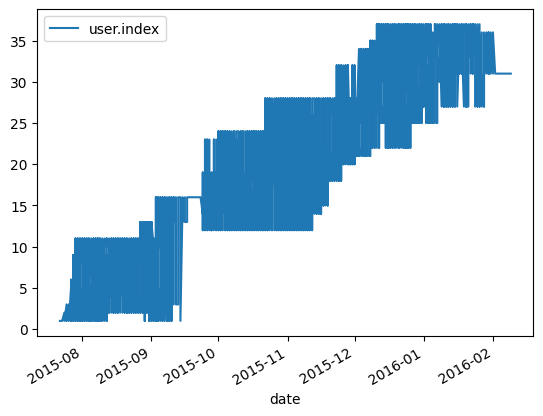

In [14]:
# checking unit overlap for better consistency
df_time_ind = df_hs[["user.index", "date"]]
df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])

df_time_ind.plot("date","user.index")
# range df
#max(df_time_ind[df_time_ind["user.index"] == 1]["date"])


## Define `transform_dnn`

### First pass: assuming all trials start at the same time

In [29]:
def transform_dnn(df, day_partitions = 4, day_measure = 144, units = 37):
    """
    Transfom df into shape suitable for DNN use case.

    Parameters
    ----------
    df : pandas DataFrame
         a matrix of size Z x 10 (with a set of properties to be defined)
         ...
    day_partitions : int
        The number of partitions to split an individual day into. The 
        default value is 4. Maximally, the value of day_partitions is 
        day_measure.
    day_measure : int
        The number of measurements per "day" in df. The default is 144,
        which aligns with the measurements per day in the HeartSteps dataset.
    units : int
        The number of units in df. Default is 37 (in line with the HeartSteps dataset)        
    Returns
    ----------
    tuple (M, A)
    where M is a units x (day_partitions * D) x (day_measure / day_partitions) np array 
    that contains the outcome vectors of interest and A is a np array shape units x (day_partitions * D)
    that indicates in which unit/time combination a treatment was observed.
    D is the maximum length of days observed among all unit trials.
    """
    # first, find the maximum trial length in days
    # units are 1-indexed
    max_days = 0
    num_days = []
    for i in range(1, units + 1):
        len_i = len(df[df['user.index'] == i]) // day_measure
        num_days.append(len_i)
        if len_i > max_days:
            max_days = len_i
    # init M and A
    M = np.zeros((units, day_partitions * max_days, day_measure // day_partitions))
    A = np.zeros((units, day_partitions * max_days))
    
    for i in range(units):
        # note: i is used to index into M and A.
        # unit_ind is used to retrieve unit specific values from df
        unit_ind = i + 1
        
        # slice by unit
        df_unit = df.loc[df["user.index"] == unit_ind]
        
        # pad first to max trial length to maintain partition size across units
        trial_steps = df_unit["steps"].to_numpy()
        trial_trt = df_unit["treatment"].to_numpy()
        if num_days[i] < max_days:
            # pad with 0s, step values are masked by trt
            pad = np.empty((max_days - num_days[i]) * day_measure)
            pad.fill(np.nan)
            trial_steps = np.append(trial_steps, pad)
            pad_trt = np.zeros((max_days - num_days[i]) * day_measure)
            trial_trt = np.append(trial_trt, pad_trt)
            
        # first split into days, then into partitions
        lst_days = np.split(trial_steps, max_days)
        parts = np.array([np.split(x, day_partitions) for x in lst_days])
         
        # Shape of parts is max_days x day_partitions x (day_measure // day_partitions)
        # Flatten along d dimension to achieve (day_partitions * max_days) x (day_measure // day_partitions) shape
        unit_parts = parts.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # Repeat for treatment col. 
        lst_days_trt = np.split(trial_trt, max_days)
        parts_trt = np.array([np.split(x, day_partitions) for x in lst_days_trt])
        unit_trt = parts_trt.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # if any of the trt values within the partition is 1, set the value in the final array to 1
        # if the user is unavailable for any period during the partition and does not receive treatment,
        # then the value in the masking array is 2
        mask_1 = np.any(unit_trt == 1, axis = 1)
        # only want to have 2 in the final array where 2 is the only non-observed value
        mask_2 = np.logical_and(np.any(unit_trt == 2, axis = 1), np.logical_not(mask_1))
        
        unit_trt_agg = np.zeros(unit_trt.shape[0])
        # unit_trt_agg = unit_trt.any(axis = 1).astype(int)
        unit_trt_agg[mask_1] = 1
        unit_trt_agg[mask_2] = 2
        
        M[i] = unit_parts
        A[i] = unit_trt_agg
        A = A.astype('int32')
    return M, A
    

## Testing `transform_dnn` with simulated symmetrical data

We create a small test dataset as a proof of concept of the above data transformation. This data set will have 3 units over a time span of 4 days, with 12 measurements a day. We partition each day into 3 segments (4 measurements per partition). The treatment is randomly applied across each day and time span. This is a simpler example than the actual use case, as the number of days within the trial is consistent for all users. See the section below for a more complex example.

In [ ]:
# create test set

# user inds
u1 = np.repeat(1, 12 * 4)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 4)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
u2_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
u3_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

# time of measurements
#single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_symtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"]) 
#df_symtest["date_time"] = pd.concat([single, single, single]).reset_index(drop = "True")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
  display(df_symtest)

Now that we have created our test set, we can use `transform_dnn_pad` to demonstrate the desired transformation properties.

In [41]:
M, A = transform_dnn(df_symtest, day_partitions = 3, day_measure = 12, units = 3)
M

array([[[5., 2., 8., 4.],
        [7., 9., 4., 6.],
        [5., 3., 4., 3.],
        [9., 8., 5., 3.],
        [5., 3., 8., 3.],
        [7., 4., 6., 5.],
        [5., 8., 5., 1.],
        [6., 7., 6., 3.],
        [1., 7., 3., 5.],
        [2., 2., 4., 3.],
        [2., 5., 2., 6.],
        [3., 2., 7., 7.]],

       [[7., 5., 2., 4.],
        [2., 7., 9., 8.],
        [5., 7., 7., 2.],
        [5., 6., 9., 2.],
        [8., 2., 6., 1.],
        [1., 7., 1., 1.],
        [2., 4., 6., 6.],
        [1., 1., 3., 5.],
        [3., 8., 8., 7.],
        [9., 5., 3., 7.],
        [2., 2., 6., 4.],
        [3., 2., 5., 5.]],

       [[4., 5., 9., 4.],
        [0., 7., 7., 4.],
        [3., 2., 3., 0.],
        [6., 3., 1., 2.],
        [8., 4., 6., 3.],
        [4., 9., 7., 9.],
        [6., 6., 7., 6.],
        [3., 7., 7., 3.],
        [1., 1., 4., 6.],
        [8., 1., 9., 9.],
        [2., 9., 2., 4.],
        [8., 3., 3., 4.]]])

In [43]:
A

array([[1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 2, 1],
       [2, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0],
       [1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0]])

## Testing `transform_dnn` on simulated asymmetrical data

Next, we test the function on a dataset with asymmetrical trial periods. As before, we will have 3 units, but this time, one of the units has a longer 6 day trial period. The remaining units have a 4 day trial period. There are still 12 measurements a day, and each day has 3 segments.

In [49]:
# create test set
# user inds, u1 has 6 day trial period
u1 = np.repeat(1, 12 * 6)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 6)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1, 2], 12 * 6, p=[0.7, 0.2, 0.1])
u2_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
u3_trt = np.random.choice([0, 1, 2], 12 * 4, p=[0.7, 0.2, 0.1])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

#single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
#longer = pd.Series(pd.date_range("2024-06-14", "2024-06-20", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_asymtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
#df_asymtest["date_time"] = pd.concat([longer, single, single]).reset_index(drop = "True")
df_asymtest

,user.index,steps,treatment
0,1,1,0
1,1,7,0
2,1,5,0
3,1,6,0
4,1,1,0
...,...,...,...
163,3,5,0
164,3,7,0
165,3,7,0
166,3,4,0


In [50]:
M_a, A_a = transform_dnn(df_asymtest, day_partitions = 3, day_measure = 12, units = 3)

In [51]:
M_a

array([[[ 1.,  7.,  5.,  6.],
        [ 1.,  1.,  7.,  2.],
        [ 4.,  6.,  7.,  8.],
        [ 4.,  2.,  9.,  4.],
        [ 3.,  1.,  6.,  7.],
        [ 5.,  2.,  5.,  3.],
        [ 8.,  6.,  8.,  8.],
        [ 5.,  3.,  3.,  9.],
        [ 4.,  8.,  7.,  8.],
        [ 1.,  2.,  5.,  1.],
        [ 5.,  5.,  9.,  6.],
        [ 3.,  5.,  9.,  8.],
        [ 9.,  5.,  7.,  3.],
        [ 6.,  9.,  5.,  9.],
        [ 7.,  4.,  7.,  1.],
        [ 9.,  7.,  3.,  6.],
        [ 1.,  3.,  1.,  2.],
        [ 7.,  9.,  3.,  4.]],

       [[ 7.,  4.,  8.,  5.],
        [ 8.,  7.,  9.,  3.],
        [ 6.,  3.,  3.,  6.],
        [ 8.,  4.,  1.,  2.],
        [ 3.,  8.,  3.,  4.],
        [ 7.,  5.,  9.,  1.],
        [ 1.,  1.,  3.,  4.],
        [ 7.,  8.,  4.,  4.],
        [ 6.,  9.,  8.,  9.],
        [ 9.,  2.,  6.,  8.],
        [ 8.,  3.,  6.,  1.],
        [ 5.,  3.,  4.,  3.],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        

In [52]:
A_a

array([[0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 1],
       [1, 0, 1, 1, 0, 1, 0, 0, 1, 2, 0, 1, 0, 0, 0, 0, 0, 0],
       [1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0]])

## Test `transform_dnn` on HeartSteps dataset

Finally, we test `transform_dnn` on its primary use case, the HeartSteps dataset. We use the `treatment` indicator as defined above.

We can see that there are 37 units. Time statistics run from 9:05 to 21:00 at 5 minute intervals, yielding 12 observations per hour for 12 hours. This means that there are 144 measurements per day. We will demonstrate by partitioning the data into 4 sections per day (i.e. each section has 36 measurements). We may later adjust this measure to optimize neighborhood size/granularity of outcome.

In [111]:
# note/question: it seems that 4 measurements may be too granular to find enough neighbors
M_hs, A_hs = transform_dnn(df_hs, day_partitions = 4, day_measure = 144, units = 37)

In [60]:
with np.printoptions(threshold=np.inf):
    print(M_hs[0, :, :])

[[  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  67. 115.]
 [ 60.   0.  61.   0. 169.   0.   0. 524. 324.   0.  26.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0. 212. 396. 457. 246.]
 [  0. 102.   0.   0.   0.   0.   0.  38.   0.   0.  64. 102.]
 [  0. 123.  74. 221.   0.   0. 260. 154.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.  62.   0.  60. 170.  28.]
 [326.  25.   0.   0.   0.   0.   0.  92.  21.  57.   0.  25.]
 [135.  22.   0.   0.  72.  32.  70.  70. 108.  68.  25.   0.]
 [ 83.  31.  18.   0.   0.   0.  93.  33.  56. 135. 365. 580.]
 [584. 584. 576. 558. 523.  88. 229.   0.   0.   0.   0. 140.]
 [  0.   0.   0.  92.  27. 227.   0.   0.   0. 156. 122.  89.]
 [590. 587. 279.   4. 113. 131.   0.   0.   0.   0.   0.   0.]
 [136. 101.  12.  89. 129.  60. 148.  81.  65.   0.  44.   0.]
 [ 88. 196.  50.  54.  89. 210.  52. 194. 143. 121. 294. 126.]
 [206. 147. 277. 350. 119. 147. 157.   0. 183. 349. 204

In [112]:
with np.printoptions(threshold=np.inf):
  print(A_hs)
print(len(A_hs[A_hs == 0]))

[[0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 1 0 0 0 1
  0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1
  0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 1 0
  0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0 1 1 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
  0 0 0 0 0 1 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0
  0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0

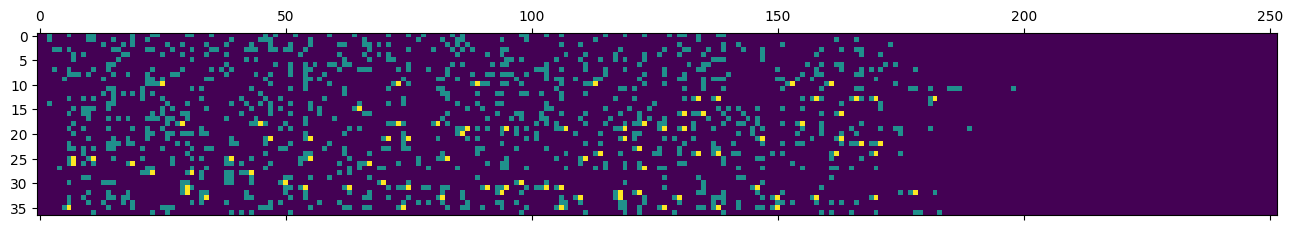

In [113]:
matshow(A_hs, aspect = 'auto')

### NN feasibility of mean-flattened Heartsteps data

First, we want to get a sense of how many observed (treated) values we have, since it seems that the treatment is applied relatively infrequently. If we have too few of these observed values, it could limit the number of potential neighbors that we could use to impute value.

In [70]:
nz_e = len(np.nonzero(A_hs)[0])
print("There are " + str(nz_e) + " nonzero entries")
print("The ratio of nonzero to zero entries is " + str(nz_e / (A_hs.size)))  

There are 1619 nonzero entries
The ratio of nonzero to zero entries is 0.05787930787930788


A $\sim\frac{1}{20}$ of zero to nonzero entries is pretty low. Let's see how it might affect average potential neighborhood size. To do this, we examine each zero entry in the masking matrix and consider how many possible neighbors could be used to impute it. Then we take the average number of possible neighbors.

In [71]:
# this is using item-item or time-time
total_pos_nn = 0
obs = np.nonzero(A_hs == 0)
for i in range(len(obs[0])): 
    total_pos_nn += np.sum(A_hs[obs[0][i], :])
print(total_pos_nn / len(obs[0]))
    

59.83823473608318


## Li 2019 Nearest Neighbors Implementation

We implement the user-user nearest neighbors algorithm as defined in Nearest Neighbors for Matrix Estimation Interpreted as Blind Regression for Latent Variable Model (Li et al. 2019). More specifically, we construct Algorithm 2, which can be found in Section III [here](https://arxiv.org/abs/1705.04867).

First, to align the NN implementation with the data format considered above, we define a function to collapse the partitioned measurements dimension (3rd dim) to its mean. Then, we construct the necessary functions as defined in Li 2019.

In [114]:
def mean_collapse(A, d = 2):
    """
    Returns A (3d array) with dth dimension collapsed as mean
    """
    return np.nanmean(A, axis = d)

def dissim_col(O, M, u, v):
    """
    Returns the col dissimilarity between cols u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a cols in O
    v : the index of a col in O

    Returns
    ----------
    d_col : the col dissimilarity between u and v (float)
    """
    obv_col_mask = M[:, u] * M[:, v]
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[:, u] - O[:, v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd
    
    
def dissim_row(O, M, u, v):
    """
    Returns the row dissimilarity between rows u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a row in O
    v : the index of a row in O

    Returns
    ----------
    d_row : the row dissimilarity between u and v (float)
    """
    obv_col_mask = M[u] * M[v]
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[u] - O[v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd

def nearest_neighbors(O_1, u, M, eta, variation = "user-user"):
    """
    Returns the B neighborbood around u using rows/cols in O_1 within
    radius eta. 
    
    Parameters
    ----------
    O_1 : a matrix of size c x d
    u : index of row/col u in O_1 and M
    M : a masking matrix of size c x d that
        dictates which entries of O_1 are known 
    eta : radius of B neighborhood
    variation : "user-user", "item-item" dictates which variation
                of nearest neighbors is being used. Default: "user-user"
    
    Returns
    ----------
    B : neighborhood (indicies of most similar rows/cols)
        with radius eta
    """
    if variation == "item-item":
        dissims = np.array([dissim_col(O_1, M, u, v) for v in range(len(O_1[0]))])
    else:
        dissims = np.array([dissim_row(O_1, M, u, v) for v in range(len(O_1))])        
    # remove u from neighbors
    #dissims = np.delete(dissims, u, 1)
    B = np.nonzero(dissims <= eta)
    return B
    
    
    
def estimate_li_nn(Z, M, eta):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    
    Returns
    ----------
    A_hat : the estimate of partially unobvserved matrix A
    """
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for u in range(m):
        for v in range(n):
            # sample splitting: artificially mask out values in the column of the
            # cell we are interested in
            O_1 = Z.copy()
            O_2 = Z[:, j]
            M_v = M.copy()
            M_v[:,j] = 0
            u_neighbors = nearest_neighbors(O_1, u, M_v, eta)
            # only select observed neighbors
            mask = M[u_neighbors, v]
            pos_nn = Z[u_neighbors, v]
            masked_nn = pos_nn[mask == 1]
            if not len(masked_nn):
                A_hat[u, v] = 0
            else:
                A_hat[u, v] = np.nanmean(masked_nn)
    return A_hat

def estimate_li_nn_inds(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (user-user variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
        # sample splitting: artificially mask out values in the column of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[:, j]
        M_j = M.copy()
        M_j[:,j] = 0
        u_neighbors = nearest_neighbors(O_1, u, M_j, eta)
        mask = M[u_neighbors, j]
        pos_nn = Z[u_neighbors, j]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
        
def estimate_li_nn_inds_cols(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (item-item variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
#         O_1  = np.delete(Z, u, axis = 0)
#         O_2 = Z[u, :]
#         M_j = np.delete(M, u, axis = 0)
        # sample splitting: artificially mask out values in the row of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[u, :]
        M_u = M.copy()
        M_u[u, :] = 0
        
        j_neighbors = nearest_neighbors(O_1, j, M_u, eta, variation = "item-item")
        mask = M[u, j_neighbors]
        pos_nn = Z[u, j_neighbors]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat

# using the indexing strategy i am currently using, A_hat and A are both 1 dimensional. This might change.
def mse(A_hat, A):
    """
    Returns the mean squared error of estimate A_hat from ground truth A
    """
    return np.nanmean((A_hat - A)**2)

### Checking Li 2019 implementation correctness with worked example

In order to look for bugs in our cross validation and Li 2019 implementations, we create a sample dataset with some nice properties and compute the similarities by hand. This doesn't guarantee correctness, but it will catch simple errors/mistakes in understanding.

To start, we create a simulated datasest with 6 users over a two day trial period. There are 6 measurements per day and each day is broken into 3 segments. 3 of the users (A, B, and C) are similar to each other (roughly more steps in the evening/last measurement periods in the day) and the other 3 users (D, E, F) are different from the first 3 and similar to each other (roughly more steps in the morning/early measurement periods.  

Let's suppose the matrix is fully observed. To simulate a validation set, we mask out one segement for each user - these are the values we will try to impute.

In [84]:
# user inds
uA = np.repeat(1, 6 * 2)
uB = np.repeat(2, 6 * 2)
uC = np.repeat(3, 6 * 2)

uD = np.repeat(4, 6 * 2)
uE = np.repeat(5, 6 * 2)
uF = np.repeat(6, 6 * 2)

user_index = np.concatenate((uA, uB, uC, uD, uE, uF))

# step measurements
steps_uA = [1, 1, 2, 3, 5, 9, 1, 1, 3, 4, 5, 10]
steps_uB = [0, 2, 2, 4, 5, 11, 0, 2, 3, 3, 4, 12]
steps_uC = [0, 0, 2, 5, 7, 10, 2, 2, 1, 5, 6, 9]

steps_uD = [10, 5, 4, 3, 1, 1, 9, 5, 3, 2, 1, 1]
steps_uE = [12, 4, 3, 3, 2, 0, 11, 5, 4, 2, 2, 0]
steps_uF = [9, 6, 5, 1, 2, 2, 10, 7, 5, 2, 0, 0]
steps = np.concatenate((steps_uA, steps_uB, steps_uC, steps_uD, steps_uE, steps_uF))

# treatment indicators
trt_uA = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uB = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uC = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

trt_uD = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uE = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uF = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

#single = pd.Series(pd.date_range("2024-06-14", "2024-06-16", inclusive = "left", freq = '4h'))

trt = np.concatenate((trt_uA, trt_uB, trt_uC, trt_uD, trt_uE, trt_uF))
final_np = np.stack((user_index, steps, trt), axis = 1)
df_nn_test = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
#df_nn_test["date_time"] = pd.concat([single, single, single, single, single, single]).reset_index(drop = "True")
df_nn_test


,user.index,steps,treatment
0,1,1,1
1,1,1,0
2,1,2,1
3,1,3,0
4,1,5,0
...,...,...,...
67,6,7,1
68,6,5,1
69,6,2,1
70,6,0,0


In [85]:
data_full, mask = transform_dnn(df_nn_test, day_partitions = 3, day_measure = 6, units = 6)

In [86]:
data_full

array([[[ 1.,  1.],
        [ 2.,  3.],
        [ 5.,  9.],
        [ 1.,  1.],
        [ 3.,  4.],
        [ 5., 10.]],

       [[ 0.,  2.],
        [ 2.,  4.],
        [ 5., 11.],
        [ 0.,  2.],
        [ 3.,  3.],
        [ 4., 12.]],

       [[ 0.,  0.],
        [ 2.,  5.],
        [ 7., 10.],
        [ 2.,  2.],
        [ 1.,  5.],
        [ 6.,  9.]],

       [[10.,  5.],
        [ 4.,  3.],
        [ 1.,  1.],
        [ 9.,  5.],
        [ 3.,  2.],
        [ 1.,  1.]],

       [[12.,  4.],
        [ 3.,  3.],
        [ 2.,  0.],
        [11.,  5.],
        [ 4.,  2.],
        [ 2.,  0.]],

       [[ 9.,  6.],
        [ 5.,  1.],
        [ 2.,  2.],
        [10.,  7.],
        [ 5.,  2.],
        [ 0.,  0.]]])

In [87]:
mask

array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

First, we take the mean of the partitioned dimension to achieve the 2D structure.

In [88]:
data = mean_collapse(data_full)
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

Next, let's calculate the dissimilarities between each row. This is the mean squared difference between overlapping observed values. 

Dissim A-B: $\frac{((3 - 2.5)^2 + (1 - 1)^2 + (3.5 - 3.0)^2 + (7.5 - 8)^2)}{4} = \frac{0.75}{4} = 0.1874$

Dissim A-C: $\frac{(1-0)^2 + (3.5 - 2.5)^2 + (1)^2 + (0.5)^2 + 0^2}{4} = \frac{3.25}{4} = 0.8125$

Dissim A-D: $\frac{6.5^2 + 1^2 + 6^2 + 1^2 + 6.5^2}{5} = \frac{122.5}{5} = 24.5$

Dissim A-E: $\frac{0.5^2 + 6^2 + 7^2 + 6.5^2}{4} = 31.875$

Dissim A-F: $\frac{6.5^ + 0.5^2 + 7.5^2 + 0}{4} = 24.6875$ 

Dissim B-C: $\frac{0.5^2 + 0.5^2 + 1^2 + 0^2}{4} = 0.375$

Dissim B-D: $\frac{0.5^2 + 6^2 + 0.5^2 + 7^2}{4} = 21.375$

Dissim B-E: $\frac{0^2 + 7^2 + 7^2 + 0^2 + 7^2}{5} = 29.4$

Dissim B-F: $\frac{0^2 + 6^2 + 7.5^2 + 0.5^2}{4} = 23.125$

Dissim C-D: $\frac{7.5^2 + 0^2 + 5^2 + 0.5^2}{4} = 20.375$

Dissim C-E: $\frac{0.5^2 + 7^2 + 7^2 + 0^2}{4} = 24.5625$

Dissim C-F: $\frac{7.5^2 + 0.5^2 + 6.5^2 + 6.5^2 + 0.5^2}{5} = 28.25$

Dissim D-E: $\frac{0.5^2 + 1^2 + 0.5^2 + 0^2}{4} = 0.375$

Dissim D-F: $\frac{0^2 + 0.5^2 + 0.5^2 + 1^2}{4} = 0.375$

Dissim E-F: $\frac{0^2 + 1^2 + 0.5^2 + 0.5^2}{4} = 0.375$

We can see that A-B-C and D-E-F are two distinct neighborhoods with $\eta = 1$. Given this, we impute the missing values by taking the average of the neighbors at the column where an observation is missing. 

In [89]:
inv_mask = ~(mask.astype(bool))
mask


array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

In [90]:
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

In [91]:
data_imputed = data.copy()
data_imputed[0, 2] = 8.25
data_imputed[1, 0] = 0.5
data_imputed[2, 5] = 7.75
data_imputed[3, 2] = 1.5
data_imputed[4, 0] = 7.5
data_imputed[5, 5] = 1

In [92]:
# these are the imputed predictions
pred = data_imputed[inv_mask]
pred

array([8.25, 0.5 , 7.75, 1.5 , 7.5 , 1.  ])

In [93]:
# this is the ground truth
truth = data[inv_mask]
truth

array([7. , 1. , 7.5, 1. , 8. , 0. ])

In [94]:
# the mse is:
mse(pred, truth)

0.5625

When we compute the MSE of the prediction by hand following Li 2019's method, we get 0.5625. Now we compute it using our implementation.

In [95]:
inds = np.nonzero(inv_mask)
A_hat = estimate_li_nn_inds(data_full, mask, eta = 1, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

0.5625

Now, we compute the same predictions for the item-item strategy.

In [96]:
inds = np.nonzero(inv_mask)
A_hat = estimate_li_nn_inds_cols(data_full, mask, eta = 3, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

0.875

## Cross Validation for $\eta$

Next, we implement cross-validation for the $\eta$ radius parameter. Given a dataset, an error metric, and an estimation function, we evaluate a range of values of $\eta$. 

In [105]:
# notes
    # we are only interested in the estimates that `estimate` makes for the
    # validation set in particular. For any validation fold, we must only consider observed values (need a ground truth)
    # We mask over these values to estimate, then extract the estimates using the original mask to compute the error.
    
# pick one cell to impute for the heartsteps to check correctness for Li 2019

In [121]:
def cross_validate_nn(Z, M, k, eta, estimate, error_metric):
    """
    Performs k-fold cross validation on using dataset `Z`, mask `M`, parameters `k` and `eta`,
    estimation function `estimate`, and error `error_metric`
    """
    # find observed indices and create splits off of those
    obvs_inds_x, obvs_inds_y = np.nonzero(M == 1)
    
    # shuffle the x and y coordinates in the same way to maintain valid coords
    shuf_inds = np.arange(len(obvs_inds_x))
    np.random.shuffle(shuf_inds)
    shuf_obvs_inds = np.array((obvs_inds_x[shuf_inds], obvs_inds_y[shuf_inds]))
    # split coordinates into k-folds
    folds = np.array_split(shuf_obvs_inds, k, axis = 1)
    tot_error = 0
    fin_k = k
    for i in range(k):
        # indices of the observed outcomes in the validation set in this iteration
        folds_ind = tuple(folds[i])
        # ground truth
        val_data = mean_collapse(Z[folds_ind], d = 1)
        est_mask = M.copy()
        # hide observed values in the validation set
        est_mask[folds_ind] = 0
        A_hat = estimate(Z, est_mask, eta, folds_ind)
        # extract validation points
        est_val = A_hat[folds_ind]
        err = error_metric(est_val, val_data)
        if np.isnan(err):
            err = 0
            fin_k -= 1
        tot_error += err
    # return average error over k folds
    return tot_error / fin_k
 

### Cross validation for Li (2019) NN

We use k-fold cross validation to tune hyperparameter $\eta$ for the Li (2019) NN model implemented above. We show results using k = 5 and k = # observed outcomes (LOOCV). 

In [115]:
# first, compute dissims from a subsection of the data to get a sense of the range of distances
# notation: should change later, but M_hs is Z and A_hs is M
from itertools import product
rnd_ind = np.random.choice(37, size = 10, replace = False)
all_combs = product(rnd_ind, rnd_ind)
M_hs_collapse = mean_collapse(M_hs)
for u, v in all_combs:
    print(dissim_row(M_hs_collapse, A_hs, u, v))

len(A_hs[A_hs == 1])

0.0
47026.26183127572
4849.574845679012
4840.39737654321
2403.519547325102
2785.0748456790125
17500.799897119337
37551.29429012346
2178.963888888889
802.7777777777777
47026.26183127572
0.0
10331.21836419753
10531.98865740741
2503.103652263375
10543.958179012347
12317.089377572014
12275.01868998628
24182.00910493827
4706.865850970018
4849.574845679012
10331.21836419753
0.0
11333.546810699587
3609.390174897119
841.0851337448557
1818.8320794753083
5563.70524691358
183.48225308641977
4401.891975308642
4840.39737654321
10531.98865740741
11333.546810699587
0.0
5950.9945344650205
6602.794612794613
6715.715979236813
14749.272119341564
8131.465856481482
5852.299672067901
2403.519547325102
2503.103652263375
3609.390174897119
5950.9945344650205
0.0
2009.811985596708
3119.561111111111
421.2717151675485
5867.058899176955
1023.1111111111113
2785.0748456790125
10543.958179012347
841.0851337448557
6602.794612794613
2009.811985596708
0.0
2362.550771604938
3549.59012345679
1597.4751984126983
1860.922260

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1443676286.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


1001

In [119]:
# try using HeartSteps data with eta 10 to 500? are there other hyperparameter optimizations to use? 
# k = 5
eta_range = np.arange(10, 3000, step = 100)
#eta_range = [350.]

min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 5, eta, estimate_li_nn_inds_cols, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta


C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1443676286.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


Error for eta 10: 3991.382700409934
Error for eta 110: 2981.3744080812885
Error for eta 210: 2959.336100725163
Error for eta 310: 2704.4954755888516
Error for eta 410: 2573.535824822392
Error for eta 510: 2507.482254601673
Error for eta 610: 2388.8500338999665
Error for eta 710: 2325.8096844815836
Error for eta 810: 2414.705831973935
Error for eta 910: 2403.8957552401675
Error for eta 1010: 2389.8725507831937
Error for eta 1110: 2431.783008313112
Error for eta 1210: 2340.530249067897
Error for eta 1310: 2298.3716475560527
Error for eta 1410: 2335.720243057459
Error for eta 1510: 2324.3907442476
Error for eta 1610: 2322.789177793654
Error for eta 1710: 2334.8247675159923
Error for eta 1810: 2354.6313504767504
Error for eta 1910: 2153.683405538937
Error for eta 2010: 2210.615997512317
Error for eta 2110: 2232.7585778042762
Error for eta 2210: 2324.489145773636
Error for eta 2310: 2357.4978959863124
Error for eta 2410: 2167.0175532490043
Error for eta 2510: 2129.3720227402127
Error for et

In [117]:
best_eta
min_error

2130.6276036968425

In [122]:
# k = # observed entries
k = len(np.nonzero(A_hs)[0])
min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 1009, eta, estimate_li_nn_inds_cols, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta

C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1443676286.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_19552\1443676286.py:218: RuntimeWarning: Mean of empty slice
  return np.nanmean((A_hat - A)**2)


Error for eta 10: 3946.709949992139
Error for eta 110: 2893.686866924073
Error for eta 210: 2693.9205349276835
Error for eta 310: 2450.771408892189
Error for eta 410: 2326.946851284477
Error for eta 510: 2282.836751421857
Error for eta 610: 2309.5623191489867
Error for eta 710: 2285.570638448613
Error for eta 810: 2296.792318638167
Error for eta 910: 2240.1689549275393
Error for eta 1010: 2256.393977551121
Error for eta 1110: 2244.164118785124
Error for eta 1210: 2247.171207884887
Error for eta 1310: 2239.691298939916
Error for eta 1410: 2246.389812376209
Error for eta 1510: 2256.649547376505
Error for eta 1610: 2269.3899417094417
Error for eta 1710: 2256.5184676257995
Error for eta 1810: 2176.0946318455203
Error for eta 1910: 2157.376963621682
Error for eta 2010: 2166.0171312015377
Error for eta 2110: 2153.2273542282496
Error for eta 2210: 2137.4454684820626
Error for eta 2310: 2131.8906934198144
Error for eta 2410: 2124.563919058376
Error for eta 2510: 2117.1980141871354
Error for et

In [123]:
best_eta

2810

## Kernel NN/MMD Implementation

We take the same data format as implemented in `transform_dnn` above. Unlike Li (2019), we do not wish to aggregate the measurements in each unit x time cell as a mean. Instead, we will use them to approximate the distribution from which they were drawn. Since we do not have the true distributions of any of the entries, we can validate our performance.


In [170]:
# might need more clarification on how MMD works with empirical distributions, i.e. how to find
# order statistics or values to impute etc..
# translated example
import numpy as np
# Kyuseong's implementation translated from R
def hatMMD_square(dat1, dat2):
    # Takes two data set and returns U-statistics estimator for MMD squared distance 
    val = 0
    N = dat1.shape[0]
    def square_kernel(x, y):
        return (np.sum(x*y) + 1)**2
    def rbf_kernel(x, y):
    # what to put here - in other implementaion of rbf, had bandwidth ranges
        sigma2 = 5
        return np.exp(-0.5*np.linalg.norm(x - y, axis = 1)**2 / (2 * sigma2))

    for i in range(N - 1):
        for j in range(i + 1, N):
            val += rbf_kernel(dat1[i, :], dat1[j, :]) + rbf_kernel(dat2[i, :], dat2[j, :]) - 2*rbf_kernel(dat1[i, :], dat2[j, :])
    return 2*val/(N*(N - 1))

In [173]:
hatMMD_square(np.array([[[111], [1]], [[2], [2]], [[3], [3]]]), np.array([[[1000], [2000]], [[1000], [2000]], [[10000000], [1000]]]))

array([0.65040981, 1.24039653])

In [177]:
def rbf_kernel(x, y):
    """
    Computes the rbf kernel matrix entry K_xy.
    Assume that x and y are c x d matrices, take the norm over the d dimension
    """
    # what to put here - in other implementaion of rbf, had bandwidth ranges
    sigma2 = 5
    return np.exp(-0.5*np.linalg.norm(x - y, axis = 1)**2 / (2 * sigma2))
    
def mmd_sqd(X_i, X_j, kern):
    """
    Return the MMD^2 distance between rows with n measurements in each cell
    X_i and X_j. Each measurement is d dimensional
    
    Parameters:
    ----------
    X_i : c x n x d array
    X_j : a c x n x d array
    kern : kernel function
    
    Returns:
    ----------
    The MMD^2 between corresponding entries in X_j and X_j.
    The output is c dimensional.
    """
    sum_h = 0
    # c are the entries in each row, n is number of measurements
    # in each entry, d is the dimension of each measurement
    c, n, d = X_i.shape
    for l, l_p in itertools.combinations(range(n), r=2):
        if l != l_p:
            x = X_i[:, l] # this is c x d dimensional
            x_p = X_i[:, l_p]
            y = X_j[:, l]
            y_p = X_j[:, l_p]
            sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y)
    
    return (1 / (n * (n - 1)) * (sum_h))
        
    
def dissim_mmd(X, A, i, j, kern):
    """
    Measures the dissimilarity between rows i and j using maximum mean discrepancies (MMD)
    
    Parameters: 
    ----------
    X : N x T x n x d array
    A : N x T matrix that denotes which entries of X are observed
    i : indice of a row in X
    j : indice of row in X
    kern : kernel function
    """
    full_mask = A[i] * A[j]
    overlap = np.sum(full_mask)
    if not overlap or i == j:
        return float("inf") 
    col_inds = np.nonzero(full_mask)
    # this removes entries that are not observed across both rows
    i_entries = X[i, col_inds]
    j_entries = X[j, col_inds]
    mmd_dissims = mmd_sqd(i_entries, j_entries, kern) 
    return np.sum(mmd_dissims) / overlap

def mmd_nn(X, A, i, eta, kern):
    """
    Returns the eta-radius neighborhood of row i in matrix X (masked by A)
    """
    dissims = np.array([dissim_mmd(X, A, i, v, kern) for v in range(len(A))])
    return np.nonzero(dissisms <= eta)
            
def mmd_est_dist(X, A, i, t, eta, inds, kern):
    """
    Compute the squared MMD barycenter of the eta-radius neighborhood as
    the estimated distribution of entries indicated by inds
    """
    row_coords, col_coords = inds
    m, n, _, _ = Z.shape # 4th dimension is feature dim d
    dist_preds = np.zeros((m, n))
    
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
        # sample splitting: artificially mask out values in the column of the
        # cell we are interested in
        O_1 = X.copy()
        #O_2 = X[:, j]
        A_j = A.copy()
        A_j[:,j] = 0
        u_neighbors = mmd_nn(O_1, A_j, u, eta, kern)
        mask = M[u_neighbors, j]
        pos_nn = Z[u_neighbors, j]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
    

In [178]:
# currently a factor of 2 off from real value
mmd_sqd(np.array([[[111], [1]], [[2], [2]], [[3], [3]]]), np.array([[[1000], [2000]], [[1000], [2000]], [[10000000], [1000]]]), rbf_kernel)

array([8.92911575e-264, 5.00000000e-001, 5.00000000e-001])

## Optimal Transport/Wasserstein Implementation

In [ ]:
# Wassertein distance -> the barycenter is described by its order statistics, which we use as
# our estimates for imputation? it seems like it becomes the mean of the (sorted)
# neighbors at the measurement level in the empirical case

In [ ]:
# is the empirical barycenter just the order statistics on the distribution, which are in turn the average of the measurements across columns?
def wasserstein2_dist(Y, A, u, i):
    """
    Return Wasserstein_2^2 distance between row u and row i of 
    observed entries in array Y

    Parameters: 
    ----------
    Y : (M + 1) x (N + 1) x n array
    A : (M + 1) x (N + 1) masking array that denotes which entries of X are observed
    u : indice of row in Y
    i : indice of row in Y
    """